# 导包

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
plt.rcParams['font.sans-serif']=['Microsoft YaHei']
plt.rcParams['font.serif']=['Microsoft YaHei']

# 获取数据

In [110]:
df=pd.read_excel('电商用户数据.xlsx')

## 看字段类型

In [111]:
df.info()
#有重复数据

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28833 entries, 0 to 28832
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   买家昵称    28833 non-null  object        
 1   付款日期    28833 non-null  datetime64[ns]
 2   订单状态    28833 non-null  object        
 3   实付金额    28833 non-null  int64         
 4   邮费      28833 non-null  int64         
 5   省份      28833 non-null  object        
 6   城市      28832 non-null  object        
 7   购买数量    28833 non-null  int64         
dtypes: datetime64[ns](1), int64(3), object(4)
memory usage: 1.8+ MB


In [112]:
df['买家昵称'].unique().size

25949

## 重复值

In [113]:
df=df.drop_duplicates()
df

,买家昵称,付款日期,订单状态,实付金额,邮费,省份,城市,购买数量
0,叫我李2,2019-01-01 00:17:59.000,交易成功,186,6,上海,上海市,1
1,0cyb1992,2019-01-01 00:59:54.000,交易成功,145,0,广东省,广州市,1
2,萝污萌莉,2019-01-01 07:48:48.000,交易成功,194,8,山东省,东营市,1
3,atblovemyy,2019-01-01 09:15:49.000,付款以后用户退款成功，交易自动关闭,84,0,江苏省,镇江市,1
4,小星期鱼,2019-01-01 09:59:33.000,付款以后用户退款成功，交易自动关闭,74,0,上海,上海市,1
...,...,...,...,...,...,...,...,...
28828,nhuliy5,2019-06-30 22:22:09.000,交易成功,144,0,湖南省,长沙市,1
28829,2ganlin7,2019-06-30 22:33:42.773,交易成功,216,0,安徽省,滁州市,1
28830,点大a,2019-06-30 22:36:52.890,交易成功,231,0,湖北省,武汉市,1
28831,8陈爷558989,2019-06-30 22:44:38.392,交易成功,99,0,广东省,深圳市,2


## 空值

In [114]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 28832 entries, 0 to 28832
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   买家昵称    28832 non-null  object        
 1   付款日期    28832 non-null  datetime64[ns]
 2   订单状态    28832 non-null  object        
 3   实付金额    28832 non-null  int64         
 4   邮费      28832 non-null  int64         
 5   省份      28832 non-null  object        
 6   城市      28831 non-null  object        
 7   购买数量    28832 non-null  int64         
dtypes: datetime64[ns](1), int64(3), object(4)
memory usage: 2.0+ MB


In [115]:
index=df.loc[df['城市'].isna(),'城市'].index

In [116]:
df=df.drop(index=index)

In [117]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 28831 entries, 0 to 28832
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   买家昵称    28831 non-null  object        
 1   付款日期    28831 non-null  datetime64[ns]
 2   订单状态    28831 non-null  object        
 3   实付金额    28831 non-null  int64         
 4   邮费      28831 non-null  int64         
 5   省份      28831 non-null  object        
 6   城市      28831 non-null  object        
 7   购买数量    28831 non-null  int64         
dtypes: datetime64[ns](1), int64(3), object(4)
memory usage: 2.0+ MB


## 异常值

In [118]:
df['买家昵称'].unique().size

25948

In [119]:
(df['付款日期'].min(),df['付款日期'].max())

(Timestamp('2019-01-01 00:17:59'), Timestamp('2019-06-30 22:46:22.511000'))

In [120]:
df['订单状态'].value_counts()

订单状态
交易成功                 27791
付款以后用户退款成功，交易自动关闭     1040
Name: count, dtype: int64

In [121]:
df['省份'].nunique()

31

In [122]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
付款日期,28831,2019-03-22 20:25:31.166887680,2019-01-01 00:17:59,2019-01-25 09:24:45.019500032,2019-03-10 02:16:15,2019-05-19 22:27:22.500000,2019-06-30 22:46:22.511000,NaN
实付金额,28831.0,126.268912,30.0,72.0,115.0,178.0,4225.0,73.773281
邮费,28831.0,0.245257,0.0,0.0,0.0,0.0,18.0,1.386481
购买数量,28831.0,1.510978,1.0,1.0,1.0,2.0,100.0,1.483524


In [123]:
# 查看99分位数表
df.describe([0.999]).T

,count,mean,min,50%,99.9%,max,std
付款日期,28831,2019-03-22 20:25:31.166887680,2019-01-01 00:17:59,2019-03-10 02:16:15,2019-06-30 18:39:11.770000128,2019-06-30 22:46:22.511000,NaN
实付金额,28831.0,126.268912,30.0,115.0,301.34,4225.0,73.773281
邮费,28831.0,0.245257,0.0,0.0,10.0,18.0,1.386481
购买数量,28831.0,1.510978,1.0,1.0,12.0,100.0,1.483524


找到异常值的方法：
1. 99%的人群是正常的，1%异常的 / 大于300的人  一刀切
2. Q3 - Q1 = IQR    Q1-1.5IQR upper  Q3+1.5IQR top
3. 统计学的角度:一组数据的三倍标准差
4. 业务

异常值处理方式:
1. 删掉
2. 使用填充手段 - 均值，众数，中位数 / 定死一个值 (max/min)

In [124]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
付款日期,28831,2019-03-22 20:25:31.166887680,2019-01-01 00:17:59,2019-01-25 09:24:45.019500032,2019-03-10 02:16:15,2019-05-19 22:27:22.500000,2019-06-30 22:46:22.511000,NaN
实付金额,28831.0,126.268912,30.0,72.0,115.0,178.0,4225.0,73.773281
邮费,28831.0,0.245257,0.0,0.0,0.0,0.0,18.0,1.386481
购买数量,28831.0,1.510978,1.0,1.0,1.0,2.0,100.0,1.483524


In [125]:
df['实付金额'].value_counts().reset_index(drop=True)

0      1493
1       858
2       833
3       741
4       731
       ... 
275       1
276       1
277       1
278       1
279       1
Name: count, Length: 280, dtype: int64

In [126]:
Q1,Q3=np.quantile(df['实付金额'],q=[0.25,0.75])

In [127]:
IQR=Q3-Q1

In [128]:
bottom=Q1-1.5*IQR
top=Q3+1.5*IQR

In [129]:
(bottom,top)

(np.float64(-87.0), np.float64(337.0))

In [130]:
df.loc[df['实付金额']>top,'实付金额']=top

In [131]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
付款日期,28831,2019-03-22 20:25:31.166887680,2019-01-01 00:17:59,2019-01-25 09:24:45.019500032,2019-03-10 02:16:15,2019-05-19 22:27:22.500000,2019-06-30 22:46:22.511000,NaN
实付金额,28831.0,126.010093,30.0,72.0,115.0,178.0,337.0,68.861556
邮费,28831.0,0.245257,0.0,0.0,0.0,0.0,18.0,1.386481
购买数量,28831.0,1.510978,1.0,1.0,1.0,2.0,100.0,1.483524


# 分析

# 对电商平台的用户分析进行统计可视化

### 查看重复购买用户

<Axes: xlabel='买家昵称'>

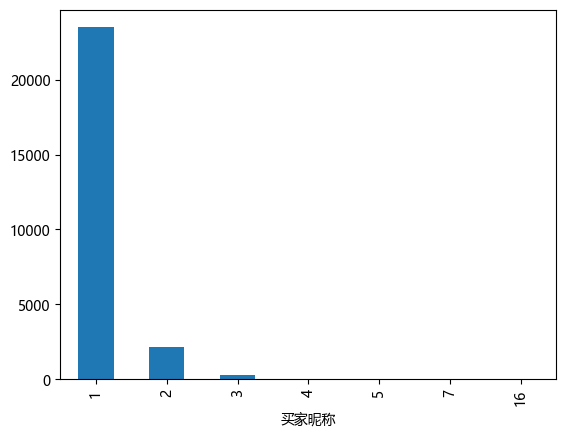

In [25]:
# 每个单量的用户统计
df.groupby('买家昵称')['买家昵称'].count().value_counts().plot(kind='bar')

<Axes: xlabel='买家昵称'>

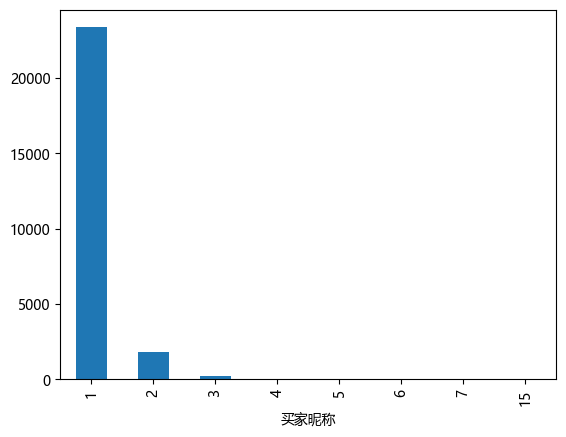

In [26]:
# 交易成功中，不同下单量的用户的统计
df.loc[df['订单状态']=='交易成功',:].groupby('买家昵称')['买家昵称'].count().value_counts().plot(kind='bar')

<Axes: xlabel='买家昵称'>

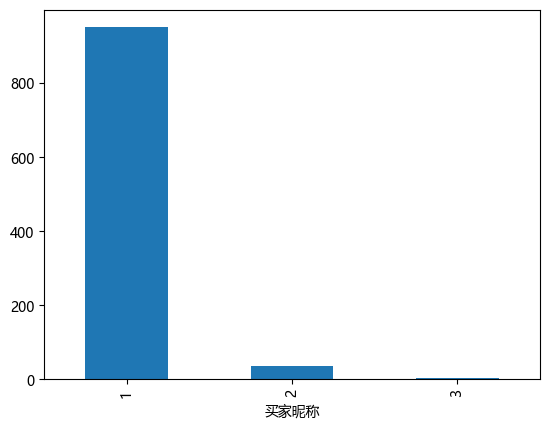

In [27]:
#交易不成功中，不同单量的用户统计
df.loc[~(df['订单状态']=='交易成功'),:].groupby('买家昵称')['买家昵称'].count().value_counts().plot(kind='bar')

<Axes: xlabel='买家昵称'>

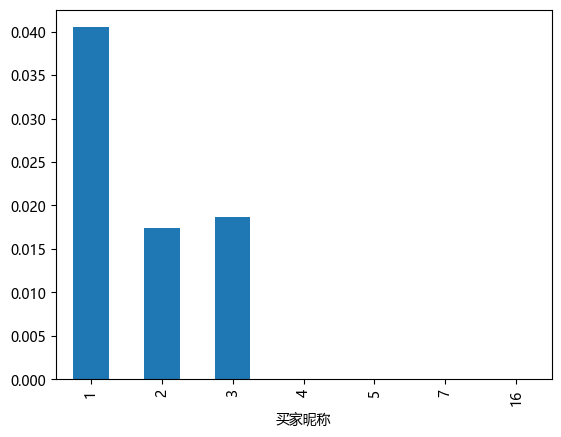

In [28]:
# 有交易记录但没有交易成功的用户统计/总交易记录的用户统计=退款率，其中下一单的用户的退款率为0.04，其最大
(df.loc[~(df['订单状态']=='交易成功'),:].groupby('买家昵称')['买家昵称'].count().value_counts()/df.groupby('买家昵称')['买家昵称'].count().value_counts()).plot(kind='bar')

### 交易时间的集中度

In [29]:
date_hour=df['付款日期'].dt.hour.value_counts().sort_index()

<Axes: xlabel='付款日期'>

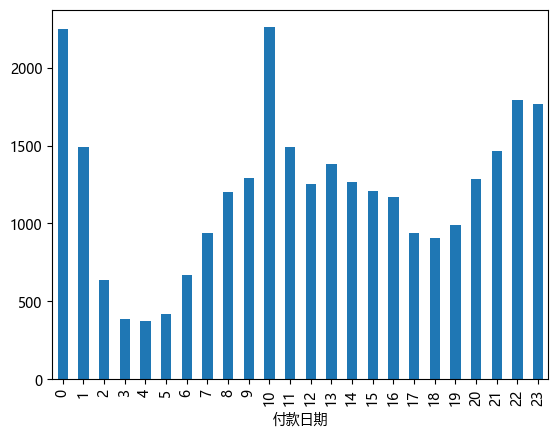

In [30]:
# 可看出用户交易时间集中在凌晨0-1点和早上10-11点
date_hour.plot(kind='bar')

### 省份

In [31]:
(df.loc[~(df['订单状态']=='交易成功'),:].groupby('省份')['买家昵称'].count()/df['省份'].value_counts()).sort_values()

省份
吉林省         0.019084
重庆          0.024145
内蒙古自治区      0.026316
江苏省         0.026578
广西壮族自治区     0.027273
上海          0.029098
云南省         0.029586
贵州省         0.030534
北京          0.031746
天津          0.032733
黑龙江省        0.034325
河南省         0.035088
四川省         0.035857
湖南省         0.037037
陕西省         0.038306
辽宁省         0.039125
河北省         0.040000
福建省         0.040089
广东省         0.041046
山东省         0.041825
海南省         0.042017
山西省         0.042169
浙江省         0.043192
新疆维吾尔自治区    0.045455
湖北省         0.049571
江西省         0.052198
安徽省         0.055195
甘肃省         0.068702
青海省         0.080000
宁夏回族自治区     0.106383
西藏自治区       0.333333
dtype: float64

通过分析发现，西藏自治区的退款率比较高，高达33%

### 退款分析

In [32]:
temp=pd.DataFrame(df.groupby(['买家昵称','订单状态'])['实付金额'].sum()).reset_index()
temp.head(5)

,买家昵称,订单状态,实付金额
0,.blue_ram,交易成功,49
1,.christiny,交易成功,183
2,.willn1,交易成功,34
3,.托托m,交易成功,37
4,0000妮,交易成功,164


In [33]:
for k,v in temp.iterrows():
    if v['订单状态']!='交易成功':
        temp.loc[k,'实付金额']=-v['实付金额']

In [34]:
temp

,买家昵称,订单状态,实付金额
0,.blue_ram,交易成功,49
1,.christiny,交易成功,183
2,.willn1,交易成功,34
3,.托托m,交易成功,37
4,0000妮,交易成功,164
...,...,...,...
26407,龙火师,交易成功,175
26408,龙魔鬼女,交易成功,87
26409,龟mil宝,交易成功,497
26410,！谢鹏逗逼？,交易成功,137


In [35]:
user_name=temp.groupby('买家昵称')['实付金额'].sum().loc[temp.groupby('买家昵称')['实付金额'].sum()<0].index

In [36]:
df.loc[df['买家昵称'].isin(user_name),:]

,买家昵称,付款日期,订单状态,实付金额,邮费,省份,城市,购买数量
3,atblovemyy,2019-01-01 09:15:49.000,付款以后用户退款成功，交易自动关闭,84,0,江苏省,镇江市,1
4,小星期鱼,2019-01-01 09:59:33.000,付款以后用户退款成功，交易自动关闭,74,0,上海,上海市,1
43,clivril_lk,2019-01-02 21:47:44.000,付款以后用户退款成功，交易自动关闭,250,0,上海,上海市,1
45,lhappyandbee,2019-01-03 00:20:40.000,付款以后用户退款成功，交易自动关闭,84,0,广东省,广州市,1
53,yzhou3,2019-01-03 10:36:12.000,付款以后用户退款成功，交易自动关闭,84,0,浙江省,杭州市,1
...,...,...,...,...,...,...,...,...
28759,小聪,2019-06-30 08:25:10.956,付款以后用户退款成功，交易自动关闭,72,0,北京,北京市,1
28764,号庞庞,2019-06-30 09:14:03.000,付款以后用户退款成功，交易自动关闭,157,8,安徽省,蚌埠市,1
28782,0jessica1128,2019-06-30 13:38:40.000,付款以后用户退款成功，交易自动关闭,43,6,浙江省,杭州市,1
28816,8ruoxi7,2019-06-30 20:08:05.000,付款以后用户退款成功，交易自动关闭,49,0,湖北省,武汉市,2


# 用户画像-RFM分层

In [40]:
rfm_order=df.loc[df['订单状态']=='交易成功',:]

In [44]:
rfm_user=rfm_order.groupby('买家昵称').agg({'付款日期':np.max,'买家昵称':np.size,'实付金额':np.sum})

C:\Users\lenovo\AppData\Local\Temp\ipykernel_41796\813503864.py:1: FutureWarning: The provided callable <function max at 0x000002A47F6F72E0> is currently using SeriesGroupBy.max. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "max" instead.
  rfm_user=rfm_order.groupby('买家昵称').agg({'付款日期':np.max,'买家昵称':np.size,'实付金额':np.sum})
C:\Users\lenovo\AppData\Local\Temp\ipykernel_41796\813503864.py:1: FutureWarning: The provided callable <function sum at 0x000002A47F6F68E0> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  rfm_user=rfm_order.groupby('买家昵称').agg({'付款日期':np.max,'买家昵称':np.size,'实付金额':np.sum})


In [47]:
last_time=rfm_user['付款日期'].max()

In [51]:
rfm_user['r']=(last_time-rfm_user['付款日期']).dt.days

In [52]:
rfm_user['f']=rfm_user['买家昵称']
rfm_user['m']=rfm_user['实付金额']

<Axes: xlabel='r'>

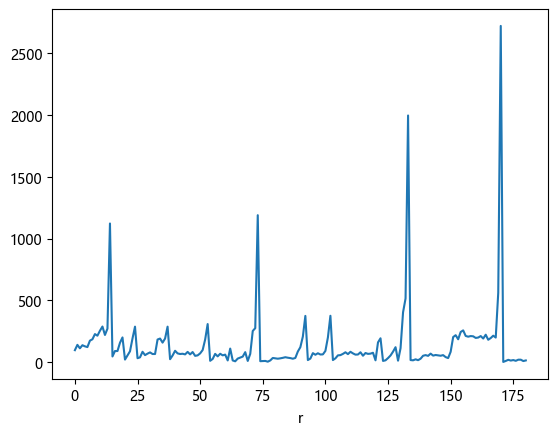

In [58]:
rfm_user['r'].value_counts().sort_index().plot()

可以看出近期

In [59]:
pd.cut(rfm_user['r'],bins=[0,120,np.inf]).value_counts()

r
(0.0, 120.0]    13625
(120.0, inf]    11696
Name: count, dtype: int64

In [62]:
rfm_user['R']=rfm_user['r'].apply(lambda x:'1' if x<=120 else '0')

In [65]:
rfm_user['f'].value_counts()

f
1     23367
2      1794
3       217
4        33
5         5
6         1
7         1
15        1
Name: count, dtype: int64

In [87]:
rfm_user['F']=rfm_user['f'].apply(lambda x: '0' if x==1 else '1')

In [80]:
pd.qcut(rfm_user['m'],q=[0,0.5,1],duplicates='drop').value_counts()

m
(29.999, 124.0]    12944
(124.0, 4158.0]    12475
Name: count, dtype: int64

In [81]:
rfm_user['M']=rfm_user['m'].apply(lambda x:'1' if x>=124 else '0')

In [82]:
rfm_user

,付款日期,买家昵称,实付金额,r,f,m,R,F,M
买家昵称,,,,,,,,,
.blue_ram,2019-02-04 17:49:34.000,1,49,146,1,49,0,1,0
.christiny,2019-01-29 14:17:15.000,1,183,152,1,183,0,1,1
.willn1,2019-01-11 03:46:18.000,1,34,170,1,34,0,1,0
.托托m,2019-01-11 02:26:33.000,1,37,170,1,37,0,1,0
0000妮,2019-06-28 16:53:26.458,1,164,2,1,164,1,1,1
...,...,...,...,...,...,...,...,...,...
龙火师,2019-04-07 08:43:00.000,1,175,84,1,175,1,1,1
龙魔鬼女,2019-04-19 22:14:24.000,1,87,72,1,87,1,1,0
龟mil宝,2019-06-19 04:26:30.589,2,497,11,2,497,1,0,1


In [88]:
rfm_user['rfm']=rfm_user['R']+rfm_user['F']+rfm_user['M']

In [89]:
rfm_user['rfm'].value_counts()

rfm
000    6481
101    6338
100    5934
001    4614
111    1242
011     526
110     209
010      75
Name: count, dtype: int64

# 策略-优惠卷投放

## 评分模型

In [136]:
df

,买家昵称,付款日期,订单状态,实付金额,邮费,省份,城市,购买数量
0,叫我李2,2019-01-01 00:17:59.000,交易成功,186,6,上海,上海市,1
1,0cyb1992,2019-01-01 00:59:54.000,交易成功,145,0,广东省,广州市,1
2,萝污萌莉,2019-01-01 07:48:48.000,交易成功,194,8,山东省,东营市,1
3,atblovemyy,2019-01-01 09:15:49.000,付款以后用户退款成功，交易自动关闭,84,0,江苏省,镇江市,0
4,小星期鱼,2019-01-01 09:59:33.000,付款以后用户退款成功，交易自动关闭,74,0,上海,上海市,0
...,...,...,...,...,...,...,...,...
28828,nhuliy5,2019-06-30 22:22:09.000,交易成功,144,0,湖南省,长沙市,1
28829,2ganlin7,2019-06-30 22:33:42.773,交易成功,216,0,安徽省,滁州市,1
28830,点大a,2019-06-30 22:36:52.890,交易成功,231,0,湖北省,武汉市,1
28831,8陈爷558989,2019-06-30 22:44:38.392,交易成功,99,0,广东省,深圳市,2


In [145]:
df['是否退单'].unique()

array([0, 1])

In [135]:
df.loc[df['订单状态']!='交易成功','购买数量']=0

In [144]:
df['是否退单']=df['订单状态'].apply(lambda x :0 if x=='交易成功' else 1)

In [146]:
df

,买家昵称,付款日期,订单状态,实付金额,邮费,省份,城市,购买数量,是否退单
0,叫我李2,2019-01-01 00:17:59.000,交易成功,186,6,上海,上海市,1,0
1,0cyb1992,2019-01-01 00:59:54.000,交易成功,145,0,广东省,广州市,1,0
2,萝污萌莉,2019-01-01 07:48:48.000,交易成功,194,8,山东省,东营市,1,0
3,atblovemyy,2019-01-01 09:15:49.000,付款以后用户退款成功，交易自动关闭,84,0,江苏省,镇江市,0,1
4,小星期鱼,2019-01-01 09:59:33.000,付款以后用户退款成功，交易自动关闭,74,0,上海,上海市,0,1
...,...,...,...,...,...,...,...,...,...
28828,nhuliy5,2019-06-30 22:22:09.000,交易成功,144,0,湖南省,长沙市,1,0
28829,2ganlin7,2019-06-30 22:33:42.773,交易成功,216,0,安徽省,滁州市,1,0
28830,点大a,2019-06-30 22:36:52.890,交易成功,231,0,湖北省,武汉市,1,0
28831,8陈爷558989,2019-06-30 22:44:38.392,交易成功,99,0,广东省,深圳市,2,0


In [199]:
score=df.groupby('买家昵称').agg({'付款日期':np.max,'买家昵称':np.size,'实付金额':np.sum,'是否退单':np.sum,'购买数量':np.sum})

C:\Users\lenovo\AppData\Local\Temp\ipykernel_41796\3207126507.py:1: FutureWarning: The provided callable <function max at 0x000002A47F6F72E0> is currently using SeriesGroupBy.max. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "max" instead.
  score=df.groupby('买家昵称').agg({'付款日期':np.max,'买家昵称':np.size,'实付金额':np.sum,'是否退单':np.sum,'购买数量':np.sum})
C:\Users\lenovo\AppData\Local\Temp\ipykernel_41796\3207126507.py:1: FutureWarning: The provided callable <function sum at 0x000002A47F6F68E0> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  score=df.groupby('买家昵称').agg({'付款日期':np.max,'买家昵称':np.size,'实付金额':np.sum,'是否退单':np.sum,'购买数量':np.sum})


In [200]:
score

,付款日期,买家昵称,实付金额,是否退单,购买数量
买家昵称,,,,,
.blue_ram,2019-02-04 17:49:34.000,1,49,0,1
.christiny,2019-01-29 14:17:15.000,1,183,0,1
.willn1,2019-01-11 03:46:18.000,1,34,0,2
.托托m,2019-01-11 02:26:33.000,1,37,0,3
0000妮,2019-06-28 16:53:26.458,1,164,0,1
...,...,...,...,...,...
龙火师,2019-04-07 08:43:00.000,1,175,0,1
龙魔鬼女,2019-04-19 22:14:24.000,1,87,0,1
龟mil宝,2019-06-19 04:26:30.589,2,497,0,2


In [201]:
last_time=score['付款日期'].max()

In [202]:
score['r']=(last_time-score['付款日期']).dt.days

In [203]:
score['购买频次']=score['买家昵称']

In [204]:
score['m']=score['实付金额']

In [205]:
score['购买数量'].value_counts()

购买数量
1      16806
2       5206
3       1704
4        786
0        529
5        361
6        222
7        127
8         74
9         42
10        30
11        17
12        10
13         9
16         6
15         4
14         4
19         3
20         2
18         1
100        1
17         1
479        1
27         1
55         1
Name: count, dtype: int64

In [206]:
score['R']=score['r'].apply(lambda x:0 if x>=120 else 1)
score['F']=score['购买频次'].apply(lambda x: 1 if x>=2 else 0)
score['M']=score['m'].apply(lambda x:1 if x>=124 else 0)

In [207]:
score['td']=score['是否退单'].apply(lambda x :0 if x>0 else 1)
score['gmsl']=score['购买数量'].apply(lambda x :1 if x>=2 else 0)

In [208]:
score

,付款日期,买家昵称,实付金额,是否退单,购买数量,r,购买频次,m,R,F,M,td,gmsl
买家昵称,,,,,,,,,,,,,
.blue_ram,2019-02-04 17:49:34.000,1,49,0,1,146,1,49,0,0,0,1,0
.christiny,2019-01-29 14:17:15.000,1,183,0,1,152,1,183,0,0,1,1,0
.willn1,2019-01-11 03:46:18.000,1,34,0,2,170,1,34,0,0,0,1,1
.托托m,2019-01-11 02:26:33.000,1,37,0,3,170,1,37,0,0,0,1,1
0000妮,2019-06-28 16:53:26.458,1,164,0,1,2,1,164,1,0,1,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
龙火师,2019-04-07 08:43:00.000,1,175,0,1,84,1,175,1,0,1,1,0
龙魔鬼女,2019-04-19 22:14:24.000,1,87,0,1,72,1,87,1,0,0,1,0
龟mil宝,2019-06-19 04:26:30.589,2,497,0,2,11,2,497,1,1,1,1,1


In [209]:
(score['R']+score['F']+score['M']+score['td']+score['gmsl']).value_counts().sort_index()

0     154
1    4620
2    9140
3    9003
4    1840
5    1191
Name: count, dtype: int64